In [79]:
import pandas as pd
import joblib

! pip install streamlit scikit-learn joblib pandas
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from scipy.stats import randint

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

In [41]:
df = pd.read_csv("used_cars_dataset.csv")

In [42]:
text_cols = ['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'AdditionInfo']
for col in text_cols:
    df[col] = df[col].fillna('unknown').astype(str).str.lower().str.strip()

In [43]:
df.head()


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,unknown,unknown,2001.0,23.0,"98,000 km",unknown,unknown,unknown,Nov-24,"honda city v teck in mint condition, valid gen...","₹ 1,95,000"
1,toyota,unknown,NaN,15.0,190000.0 km,manual,unknown,diesel,Jul-24,"toyota innova 2.5 g (diesel) 7 seater, 2009, d...","₹ 3,75,000"
2,volkswagen,unknown,2010.0,NaN,NaN,manual,first,unknown,Nov-24,"volkswagen vento 2010-2013 diesel breeze, 2010...","₹ 1,84,999"
3,unknown,swift,2017.0,7.0,NaN,manual,second,unknown,NaN,mar uti suzuki swift 2017 diesel good condition,"₹ 5,65,000"
4,maruti suzuki,unknown,2019.0,5.0,NaN,automatic,unknown,unknown,Nov-24,"maruti suzuki baleno alpha cvt, 2019, petrol","₹ 6,85,000"


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24575 entries, 0 to 24574
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         24575 non-null  str    
 1   model         24575 non-null  str    
 2   Year          19396 non-null  float64
 3   Age           18600 non-null  float64
 4   kmDriven      18344 non-null  str    
 5   Transmission  24575 non-null  str    
 6   Owner         24575 non-null  str    
 7   FuelType      24575 non-null  str    
 8   PostedDate    18355 non-null  str    
 9   AdditionInfo  24575 non-null  str    
 10  AskPrice      24575 non-null  str    
dtypes: float64(2), str(9)
memory usage: 2.1 MB


In [45]:
df = df.drop_duplicates().copy()

In [46]:
brands = [
    'maruti suzuki', 'maruti', 'suzuki', 'mercedes-benz', 'mercedes', 'land rover',
    'aston martin', 'rolls-royce', 'honda', 'toyota', 'volkswagen', 'bmw', 'ford',
    'kia', 'hyundai', 'audi', 'renault', 'mg', 'skoda', 'volvo', 'mahindra', 'tata',
    'jaguar', 'jeep', 'porsche', 'nissan', 'chevrolet', 'fiat', 'lexus', 'mini',
    'mitsubishi', 'datsun', 'isuzu', 'force', 'opel'
]

top_models = [
    'innova crysta', 'wagon r', 'grand i10', 'swift dzire', 'alto k10', 'alto 800',
    'vitara brezza', 'swift', 'dzire', 'baleno', 'innova', 'crysta', 'alto', 'creta',
    'verna', 'i20', 'i10', 'wagon r', 'fortuner', 'city', 'celerio', 'ertiga', 'kwid',
    'polo', 'vento', 'hector', 'thar', 'scorpio', 'xuv500', 'xuv700', 'nexon', 'amaze',
    'jazz', 'rapid', 'compass', 'harrier', 'safari', 'venue', 'tiago', 'seltos', 'sonet'
]

luxury_brands = [
    'bmw', 'mercedes-benz', 'audi', 'porsche', 'lexus', 'land rover',
    'jaguar', 'volvo', 'aston martin', 'mini', 'maserati', 'bentley', 'rolls-royce'
]
legacy_trusted = [
    'toyota', 'volkswagen', 'ford', 'honda', 'hyundai', 'kia',
    'nissan', 'suzuki', 'maruti suzuki', 'mahindra'
]


# Brands/models that exited the market or discontinued lines 
discontinued_brands= ['chevrolet', 'fiat', 'datsun', 'mitsubishi', 'opel']
discontinued_models = ['ecosport', 'figo', 'fiesta', 'endeavour', 'civic', 'accord', 'cr-v', 'brio', 'jazz', 'alto 800', 'omni', 'sx4', 'ritz', 'zen']

# High-volume parts-interchangeable models 
high_demand_targets = ['polo', 'fortuner', 'innova', 'swift', 'dzire', 'creta', 'scorpio', 'bolero']


In [47]:

EXCHANGE_RATE = 0.175176

def clean_price(val):
    if pd.isna(val) or str(val) in ['nan', 'unknown', '']: return np.nan
    nums = re.sub(r'[^0-9.]', '', str(val))
    if not nums or nums == '.': return np.nan
    v = float(nums)
    if v < 1000: v *= 100000  
    return v * EXCHANGE_RATE

df['Price_ZAR'] = df['AskPrice'].apply(clean_price)

print(df[['kmDriven', 'AskPrice']].dtypes)
print(df[['kmDriven', 'AskPrice']].head())

kmDriven    str
AskPrice    str
dtype: object
      kmDriven    AskPrice
0    98,000 km  ₹ 1,95,000
1  190000.0 km  ₹ 3,75,000
2          NaN  ₹ 1,84,999
3          NaN  ₹ 5,65,000
4          NaN  ₹ 6,85,000


In [48]:
def clean_km(val):
    if pd.isna(val) or str(val) in ['nan', 'unknown', '']: return np.nan
    nums = re.sub(r'[^0-9.]', '', str(val))
    return float(nums) if nums else np.nan

df['kmDriven'] = df['kmDriven'].apply(clean_km)

In [49]:
df.info()

<class 'pandas.DataFrame'>
Index: 14987 entries, 0 to 24574
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         14987 non-null  str    
 1   model         14987 non-null  str    
 2   Year          12390 non-null  float64
 3   Age           11994 non-null  float64
 4   kmDriven      11839 non-null  float64
 5   Transmission  14987 non-null  str    
 6   Owner         14987 non-null  str    
 7   FuelType      14987 non-null  str    
 8   PostedDate    11865 non-null  str    
 9   AdditionInfo  14987 non-null  str    
 10  AskPrice      14987 non-null  str    
 11  Price_ZAR     14987 non-null  float64
dtypes: float64(4), str(8)
memory usage: 1.5 MB


In [50]:
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

mask_corrupt = (df['Year'] > 2026) | (df['Year'] < 1990) | (df['Year'].isna())

df.loc[mask_corrupt & df['Age'].notna(), 'Year'] = 2026 - df.loc[mask_corrupt & df['Age'].notna(), 'Age']
df.loc[df['Age'].isna() & df['Year'].notna(), 'Age'] = 2026 - df.loc[df['Age'].isna() & df['Year'].notna(), 'Year']



In [51]:
df['Age'] = 2026 - df['Year']


In [52]:
def impute_from_text(row):
    text = row['AdditionInfo']
    brand, model, fuel, trans = row['Brand'], row['model'], row['FuelType'], row['Transmission']
    
    if brand in ['unknown', 'nan', '']:
        for b in brands:
            if b in text:
                brand = 'maruti suzuki' if b in ['maruti', 'suzuki'] else ('mercedes-benz' if b == 'mercedes' else b)
                break
    if model in ['unknown', 'nan', '']:
        for m in top_models:
            if m in text:
                model = m
                break
    if fuel in ['unknown', 'nan', '']:
        if 'diesel' in text: fuel = 'diesel'
        elif 'petrol' in text: fuel = 'petrol'
        elif any(k in text for k in ['cng', 'hybrid', 'lpg']): fuel = 'hybrid/cng'
    if trans in ['unknown', 'nan', '']:
        if any(k in text for k in ['automatic', 'amt', 'cvt', 'dct', 'dsg', ' at ']): trans = 'automatic'
        elif 'manual' in text or ' mt ' in text: trans = 'manual'
        
    return pd.Series([brand, model, fuel, trans])

df[['Brand', 'Refined_Model', 'FuelType', 'Transmission']] = df.apply(impute_from_text, axis=1)

In [53]:
def extract_engine_size(text):
    match = re.search(r'\b([0-6]\.[0-9])\s*(l|litre|cc|vtvt|crdi|tdi|tsi|sharp|titanium|gdi|mpi|ivtec|i-vtec|i-dtec)?\b', text)
    if match:
        val = float(match.group(1))
        if 0.6 <= val <= 6.5:
            return val
    if re.search(r'\b(alto|kwid|nano|eeco|omni)\b', text): return 0.8
    if re.search(r'\b(swift|baleno|i20|i10|wagon r|celerio|ignis|tiago)\b', text): return 1.2
    if re.search(r'\b(city|verna|creta|seltos|venue|nexon|amaze|ecosport)\b', text): return 1.5
    if re.search(r'\b(innova|fortuner|endeavour|xuv500|scorpio|harrier|safari)\b', text): return 2.4
    return 1.5

In [54]:
def extract_seating(text):
    match = re.search(r'\b([2-9])\s*(seater|str|seat)\b', text)
    if match:
        return int(match.group(1))
    if re.search(r'\b(innova|ertiga|xylo|hexa|carnival|safari|alcazar|gloster|bolero|marazzo|xl6|carens)\b', text):
        return 7
    return 5

In [55]:
df['Engine_Capacity'] = df['AdditionInfo'].apply(extract_engine_size)
df['Seating_Capacity'] = df['AdditionInfo'].apply(extract_seating)

In [56]:
df.dropna(subset=['Price_ZAR', 'Year', 'Age'], inplace=True)

df['kmDriven'] = df['kmDriven'].fillna(df.groupby('Refined_Model')['kmDriven'].transform('median'))
df['kmDriven'] = df['kmDriven'].fillna(df['kmDriven'].median())

df = df[(df['Price_ZAR'] >= 15000) & (df['Price_ZAR'] <= 2500000)]
df = df[(df['kmDriven'] >= 500) & (df['kmDriven'] <= 350000)]
df = df[(df['Year'] >= 2005) & (df['Year'] <= 2026)]

In [57]:
df['km_per_year'] = df['kmDriven'] / (df['Age'] + 1)
df['is_luxury'] = df['Brand'].isin(luxury_brands).astype(int)
df['Brand_Tier'] = np.where(
    df['is_luxury'] == 1, 'Luxury',
    np.where(df['Brand'].isin(legacy_trusted), 'Trusted_Legacy', 'Value_Challenger')
)
df['is_discontinued'] = (
    df['Brand'].isin(discontinued_brands) |
    df['Refined_Model'].isin(discontinued_models)
).astype(int)
df['high_demand_target'] = df['Refined_Model'].isin(high_demand_targets).astype(int)

print(f"Cleaned Dataset Shape: {df.shape}")
print(df[['Price_ZAR', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType']].isna().sum())

Cleaned Dataset Shape: (13143, 20)
Price_ZAR       0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
dtype: int64


In [58]:
if 'Refined_Model' not in df.columns:
    df[['Brand', 'Refined_Model', 'FuelType', 'Transmission']] = df.apply(impute_from_text, axis=1)
model_col = 'Refined_Model' if 'Refined_Model' in df.columns else 'model'

if 'Engine_Capacity' not in df.columns:
    df['Engine_Capacity'] = df['AdditionInfo'].apply(extract_engine_size)
if 'Seating_Capacity' not in df.columns:
    df['Seating_Capacity'] = df['AdditionInfo'].apply(extract_seating)
if 'is_luxury' not in df.columns:
    df['is_luxury'] = df['Brand'].isin(luxury_brands).astype(int)

df.dropna(subset=['Price_ZAR', 'Year', 'Age'], inplace=True)

df['kmDriven'] = df['kmDriven'].fillna(
    df.groupby(model_col)['kmDriven'].transform('median')
)
df['kmDriven'] = df['kmDriven'].fillna(df['kmDriven'].median())

df = df[(df['Price_ZAR'] >= 15000) & (df['Price_ZAR'] <= 2500000)]
df = df[(df['kmDriven'] >= 500) & (df['kmDriven'] <= 350000)]
df = df[(df['Year'] >= 2005) & (df['Year'] <= 2024)]

df['km_per_year'] = df['kmDriven'] / (df['Age'] + 1)

legacy_trusted = [
    'toyota', 'volkswagen', 'ford', 'honda', 'hyundai', 'kia',
    'nissan', 'suzuki', 'maruti suzuki', 'mahindra'
]
df['Brand_Tier'] = np.where(
    df['is_luxury'] == 1, 'Luxury',
    np.where(df['Brand'].isin(legacy_trusted), 'Trusted_Legacy', 'Value_Challenger')
)

print(f"Cleaned Dataset Shape: {df.shape}")
print(f"Remaining Missing Values:\n{df[['Price_ZAR', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType']].isna().sum()}")


Cleaned Dataset Shape: (12962, 20)
Remaining Missing Values:
Price_ZAR       0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
dtype: int64


In [59]:
df['Engine_Capacity'] = df['AdditionInfo'].apply(extract_engine_size)
df['Seating_Capacity'] = df['AdditionInfo'].apply(extract_seating)
df['is_luxury'] = df['Brand'].isin(luxury_brands).astype(int)

In [60]:

df['kmDriven'] = df['kmDriven'].fillna(df['kmDriven'].median())
df.dropna(subset=['Price_ZAR', 'Year', 'Age'], inplace=True)

In [61]:
df = df[(df['Price_ZAR'] >= 5000) & (df['Price_ZAR'] <= 3000000)]
df = df[(df['kmDriven'] >= 500) & (df['kmDriven'] <= 400000)]
df = df[(df['Year'] >= 2000) & (df['Year'] <= 2024)]

In [62]:
df['km_per_year'] = df['kmDriven'] / (df['Age'] + 1)

print(f"Cleaned Dataset Shape: {df.shape}")

Cleaned Dataset Shape: (12962, 20)


In [63]:
df['km_per_year'] = df['kmDriven'] / (df['Age'] + 1)
df['Engine_Capacity'] = df['AdditionInfo'].apply(extract_engine_size)
df['Seating_Capacity'] = df['AdditionInfo'].apply(extract_seating)

df['is_luxury'] = df['Brand'].isin(luxury_brands).astype(int)
df['Brand_Tier'] = np.where(
    df['is_luxury'] == 1, 'Luxury',
    np.where(df['Brand'].isin(legacy_trusted), 'Trusted_Legacy', 'Value_Challenger')
)

df['is_discontinued'] = (
    df['Brand'].isin(discontinued_brands) | 
    df['Refined_Model'].isin(discontinued_models)
).astype(int)

df['high_demand_target'] = df['Refined_Model'].isin(high_demand_targets).astype(int)

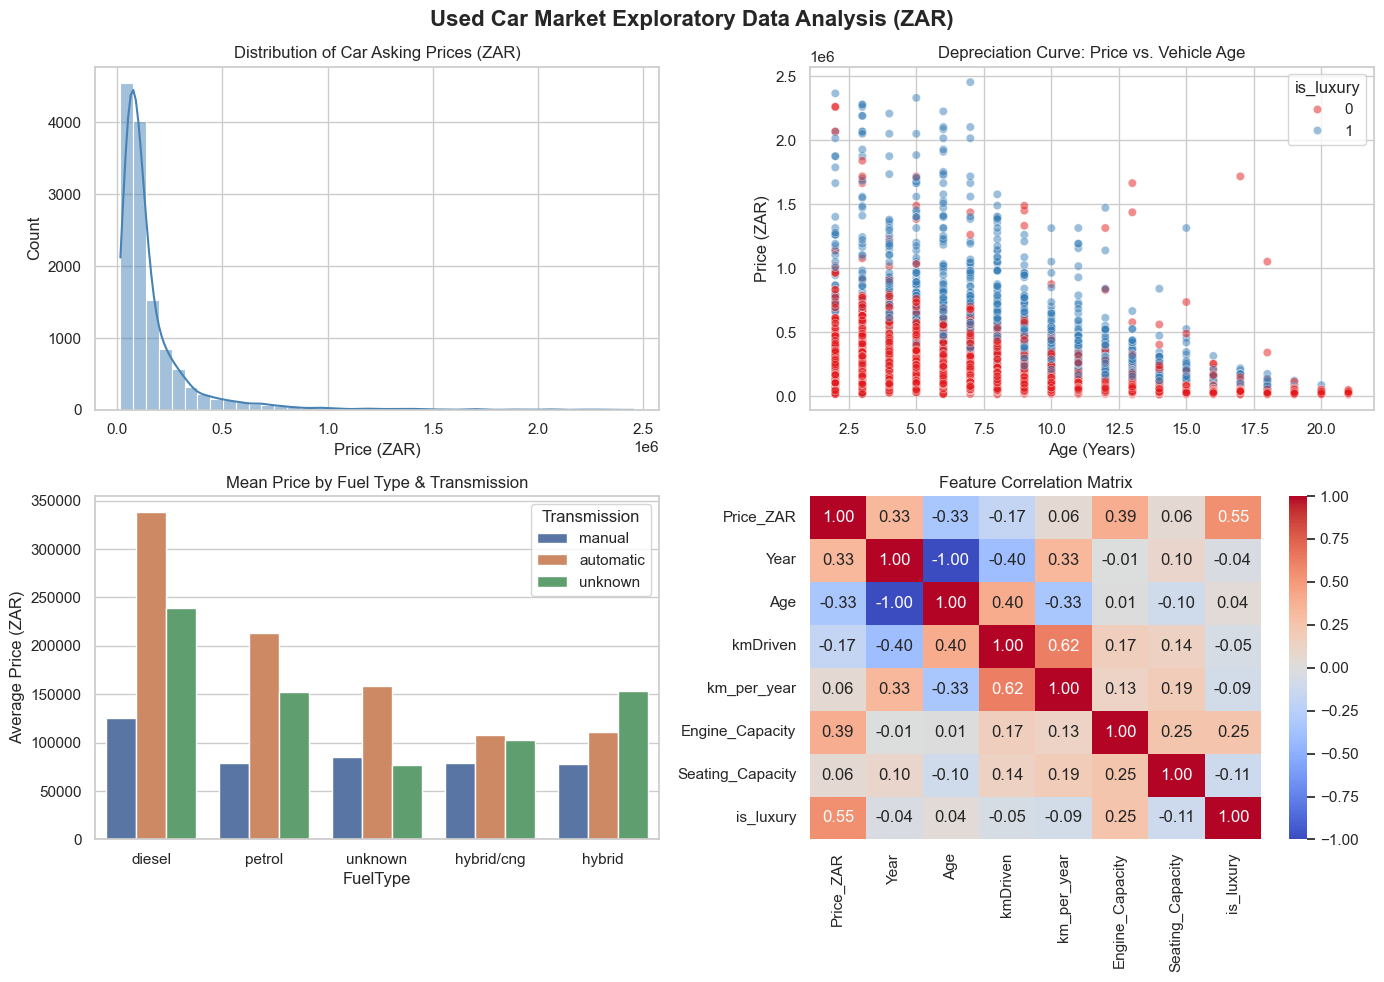

In [64]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Used Car Market Exploratory Data Analysis (ZAR)", fontsize=16, fontweight='bold')

sns.histplot(df['Price_ZAR'], bins=40, kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title("Distribution of Car Asking Prices (ZAR)")
axes[0, 0].set_xlabel("Price (ZAR)")

sns.scatterplot(data=df, x='Age', y='Price_ZAR', hue='is_luxury', alpha=0.5, ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title("Depreciation Curve: Price vs. Vehicle Age")
axes[0, 1].set_xlabel("Age (Years)")
axes[0, 1].set_ylabel("Price (ZAR)")

sns.barplot(data=df, x='FuelType', y='Price_ZAR', hue='Transmission', ax=axes[1, 0], estimator=np.mean, errorbar=None)
axes[1, 0].set_title("Mean Price by Fuel Type & Transmission")
axes[1, 0].set_ylabel("Average Price (ZAR)")

num_cols = ['Price_ZAR', 'Year', 'Age', 'kmDriven', 'km_per_year', 'Engine_Capacity', 'Seating_Capacity', 'is_luxury']
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

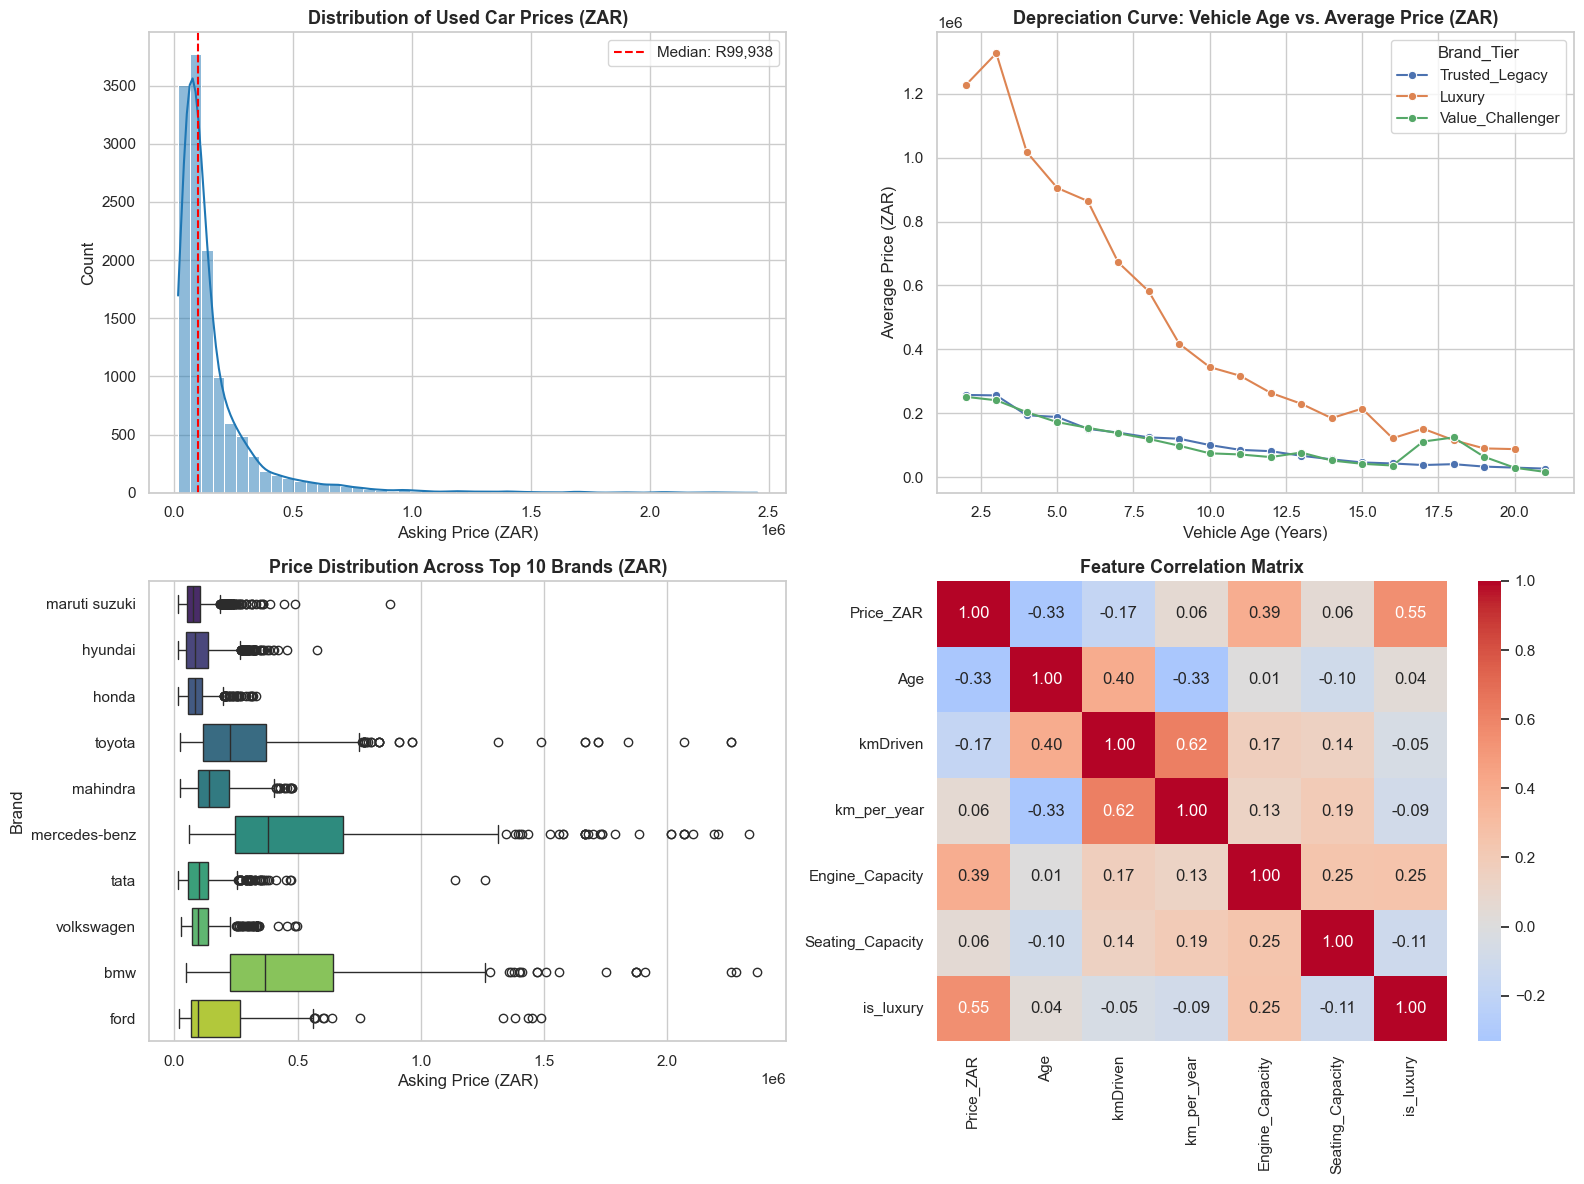

In [65]:

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Target Variable Distribution (Price in ZAR)
sns.histplot(df['Price_ZAR'], bins=50, kde=True, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].axvline(df['Price_ZAR'].median(), color='red', linestyle='--', label=f"Median: R{df['Price_ZAR'].median():,.0f}")
axes[0, 0].set_title('Distribution of Used Car Prices (ZAR)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Asking Price (ZAR)')
axes[0, 0].legend()

# Depreciation Curve: Age vs Price by Brand Tier
sns.lineplot(data=df, x='Age', y='Price_ZAR', hue='Brand_Tier', marker='o', errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title('Depreciation Curve: Vehicle Age vs. Average Price (ZAR)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Vehicle Age (Years)')
axes[0, 1].set_ylabel('Average Price (ZAR)')

# Top 10 Brands Price Spread
top_10_brands = df['Brand'].value_counts().nlargest(10).index
sns.boxplot(
    data=df[df['Brand'].isin(top_10_brands)],
    x='Price_ZAR', y='Brand', order=top_10_brands, ax=axes[1, 0], palette='viridis'
)
axes[1, 0].set_title('Price Distribution Across Top 10 Brands (ZAR)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Asking Price (ZAR)')
axes[1, 0].set_ylabel('Brand')

# Correlation Heatmap of Engineered & Numerical Features
num_cols = ['Price_ZAR', 'Age', 'kmDriven', 'km_per_year', 'Engine_Capacity', 'Seating_Capacity', 'is_luxury']
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


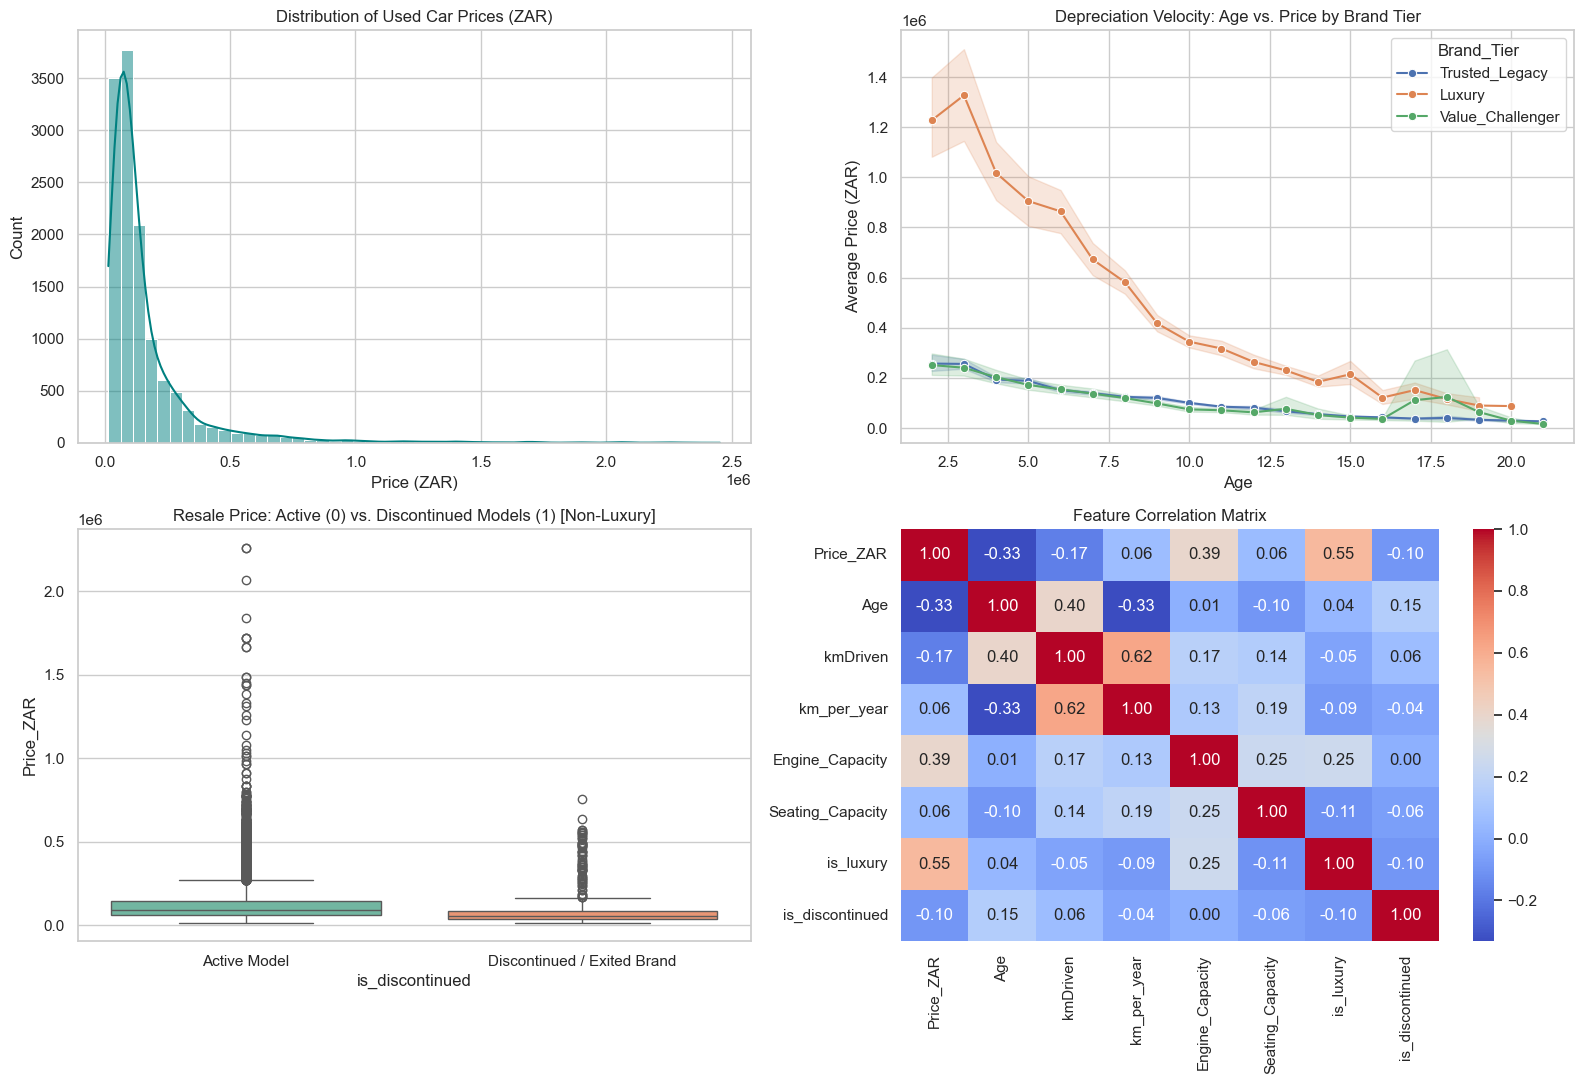

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(df['Price_ZAR'], bins=50, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Used Car Prices (ZAR)')
axes[0, 0].set_xlabel('Price (ZAR)')

sns.lineplot(data=df, x='Age', y='Price_ZAR', hue='Brand_Tier', ax=axes[0, 1], marker='o')
axes[0, 1].set_title('Depreciation Velocity: Age vs. Price by Brand Tier')
axes[0, 1].set_ylabel('Average Price (ZAR)')

sns.boxplot(data=df[df['is_luxury'] == 0], x='is_discontinued', y='Price_ZAR', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Resale Price: Active (0) vs. Discontinued Models (1) [Non-Luxury]')
axes[1, 0].set_xticklabels(['Active Model', 'Discontinued / Exited Brand'])

num_cols = ['Price_ZAR', 'Age', 'kmDriven', 'km_per_year', 'Engine_Capacity', 'Seating_Capacity', 'is_luxury', 'is_discontinued']
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()

In [67]:
df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,Price_ZAR,Refined_Model,Engine_Capacity,Seating_Capacity,km_per_year,is_luxury,Brand_Tier,is_discontinued,high_demand_target
1,toyota,unknown,2011.0,15.0,190000.0,manual,unknown,diesel,Jul-24,"toyota innova 2.5 g (diesel) 7 seater, 2009, d...","₹ 3,75,000",6.569100e+04,innova,2.5,7,11875.000000,0,Trusted_Legacy,0,1
2,volkswagen,unknown,2010.0,16.0,67000.0,manual,first,diesel,Nov-24,"volkswagen vento 2010-2013 diesel breeze, 2010...","₹ 1,84,999",3.240738e+04,vento,1.5,5,3941.176471,0,Trusted_Legacy,0,0
3,maruti suzuki,swift,2017.0,9.0,65000.0,manual,second,diesel,NaN,mar uti suzuki swift 2017 diesel good condition,"₹ 5,65,000",9.897444e+04,swift,1.2,5,6500.000000,0,Trusted_Legacy,0,1
4,maruti suzuki,unknown,2019.0,7.0,55000.0,automatic,unknown,petrol,Nov-24,"maruti suzuki baleno alpha cvt, 2019, petrol","₹ 6,85,000",1.199956e+05,baleno,1.2,5,6875.000000,0,Trusted_Legacy,0,0
5,bmw,unknown,2014.0,12.0,83000.0,unknown,first,diesel,Nov-24,"bmw x3 2.0 xdrive 20d, 2014, diesel","₹ 13,50,000",2.364876e+05,unknown,2.0,5,6384.615385,1,Luxury,0,0
6,toyota,unknown,2016.0,10.0,168000.0,manual,second,diesel,Nov-24,"toyota innova 2.5 vx 8 seater bs iv, 2014, diesel","₹ 10,25,000",1.795554e+05,innova,2.5,8,15272.727273,0,Trusted_Legacy,0,1
7,bmw,unknown,2019.0,7.0,65000.0,automatic,unknown,diesel,Nov-24,"bmw 5 series 3.0 530d m sport, 2019, diesel","₹ 59,50,000",1.042297e+06,unknown,3.0,5,8125.000000,1,Luxury,0,0
11,kia,unknown,2023.0,3.0,25000.0,automatic,unknown,diesel,Nov-24,"kia carnival premium 8 str, 2021, diesel","₹ 29,00,000",5.080104e+05,unknown,1.5,8,6250.000000,0,Trusted_Legacy,0,0
12,maruti suzuki,swift-dzire,2014.0,12.0,72700.0,manual,second,petrol,Nov-24,"maruti suzuki swift dzire vxi 1.2, 2012, petrol","₹ 2,40,000",4.204224e+04,swift-dzire,1.2,5,5592.307692,0,Trusted_Legacy,0,0
13,unknown,unknown,2009.0,17.0,121931.0,automatic,second,petrol,Nov-24,top end fully loaded automatic corolla with ...,"₹ 2,01,350",3.527169e+04,unknown,1.5,5,6773.944444,0,Value_Challenger,0,0


In [68]:
numeric_features = [
    'Age', 'kmDriven', 'km_per_year', 'Engine_Capacity', 
    'Seating_Capacity', 'is_luxury', 'is_discontinued', 'high_demand_target'
]
categorical_features = ['Brand', 'Refined_Model', 'FuelType', 'Transmission']

ordinal_features = ['Owner', 'Brand_Tier']

ordinal_categories = [
    ['first', 'second', 'third', 'fourth & above', 'unknown'],
    ['Value_Challenger', 'Trusted_Legacy', 'Luxury']
]

nominal_features = ['Brand', 'Refined_Model', 'Transmission', 'FuelType']

all_features = numeric_features + ordinal_features + nominal_features
valid_owners = {'first', 'second', 'third', 'fourth & above'}
df['Owner'] = df['Owner'].apply(lambda x: x if x in valid_owners else 'unknown')

X = df[all_features].copy()
y = df['Price_ZAR'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [69]:
results = []


def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    mae = mean_absolute_error(y_te, y_pred)
    r2 = r2_score(y_te, y_pred)
    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=5, scoring='r2').mean()
    
    results.append({
        'Model': name,
        'Test RMSE (ZAR)': round(rmse, 2),
        'Test MAE (ZAR)': round(mae, 2),
        'Test R²': round(r2, 4),
        '5-Fold CV R²': round(cv_r2, 4)
    })
    return model

In [70]:

numeric_features = [
    'Year', 'Age', 'kmDriven', 'km_per_year', 
    'Engine_Capacity', 'Seating_Capacity', 
    'is_luxury', 'is_discontinued', 'high_demand_target'
]
categorical_features = [
    'Brand', 'Refined_Model', 'Transmission', 
    'Owner', 'FuelType', 'Brand_Tier'
]

X = df[numeric_features + categorical_features]
y = df['Price_ZAR']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)


rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

print("Models trained successfully! y_pred_lr and y_pred_rf are now ready.")


Models trained successfully! y_pred_lr and y_pred_rf are now ready.


In [71]:
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"RMSE: R {rmse:,.2f}")
    print(f"MAE : R {mae:,.2f}")
    print(f"R²  : {r2:.4f}\n")

evaluate_model("Baseline Linear Regression", y_test, y_pred_lr)
evaluate_model("Random Forest (Default)", y_test, y_pred_rf)

--- Baseline Linear Regression ---
RMSE: R 111,954.23
MAE : R 56,732.31
R²  : 0.7409

--- Random Forest (Default) ---
RMSE: R 94,993.05
MAE : R 37,804.67
R²  : 0.8134



In [72]:

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

param_dist = {
    'n_estimators': randint(80, 150),       
    'max_depth':[10, 20, 30, None],               
    'min_samples_split': randint(4, 12),
    'min_samples_leaf': randint(2, 6),
    'max_features': ['sqrt', 0.5]           
}


rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    rf_base, 
    param_distributions=param_dist, 
    n_iter=8,                             
    cv=3, 
    scoring='r2', 
    random_state=42, 
    n_jobs=-1
)
random_search.fit(X_train_processed, y_train)

best_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', random_search.best_estimator_)
])

y_pred = best_rf.predict(X_test)
residuals = y_test - y_pred

results.append({
    'Model': 'Tuned: Random Forest',
    'Test RMSE (ZAR)': round(np.sqrt(mean_squared_error(y_test, y_pred)), 2),
    'Test MAE (ZAR)': round(mean_absolute_error(y_test, y_pred), 2),
    'Test R²': round(r2_score(y_test, y_pred), 4),
    'CV R²': round(random_search.best_score_, 4)
})


--- Overfitting & Underfitting Diagnostic ---
Baseline Linear Regression -> Train R²: 0.7611 | Test R²: 0.7409
Tuned Random Forest        -> Train R²: 0.8940 | Test R²: 0.7950


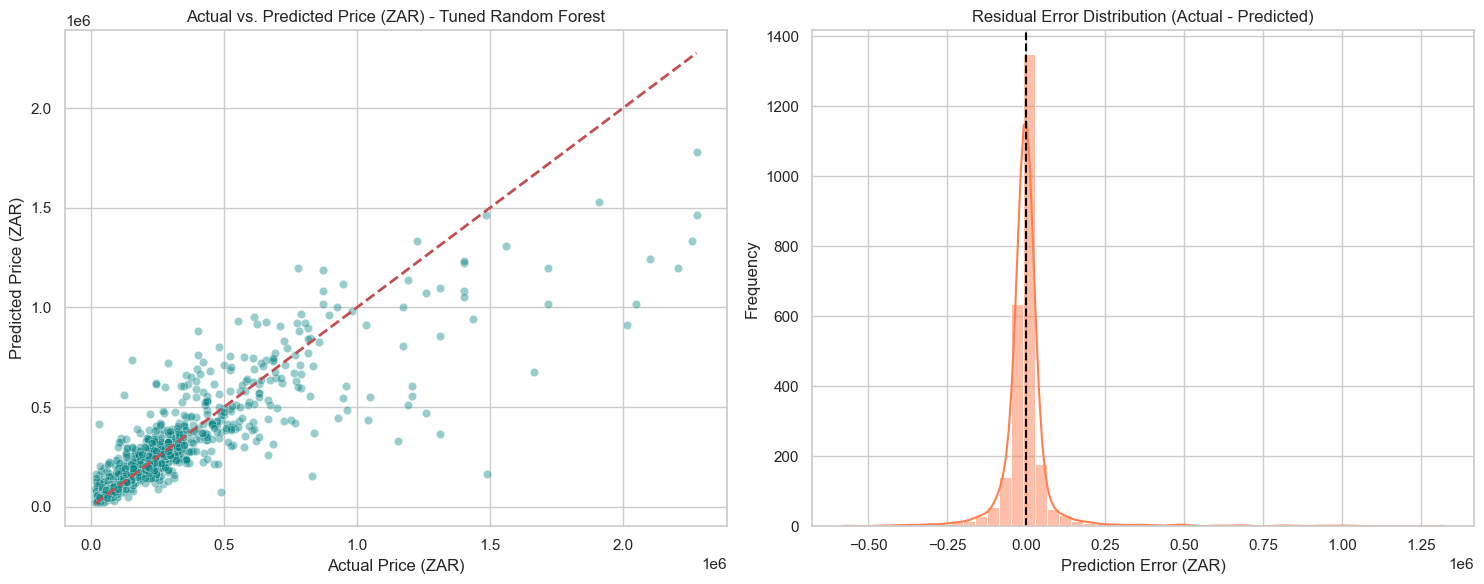


--- Top 5 Largest Prediction Errors ---
        Brand     Refined_Model   Year  kmDriven  Actual_ZAR  Predicted_ZAR  Abs_Error_ZAR
       toyota           unknown 2021.0   42000.0   1488996.0      165804.55     1323191.45
   land rover range rover sport 2019.0   55000.0   2014524.0      913878.91     1100645.09
   land rover           unknown 2022.0   65000.0   2049559.2     1015053.57     1034505.63
mercedes-benz               gls 2022.0   42000.0   2207217.6     1198459.63     1008757.97
       toyota           unknown 2023.0   30000.0   1664172.0      674803.57      989368.43


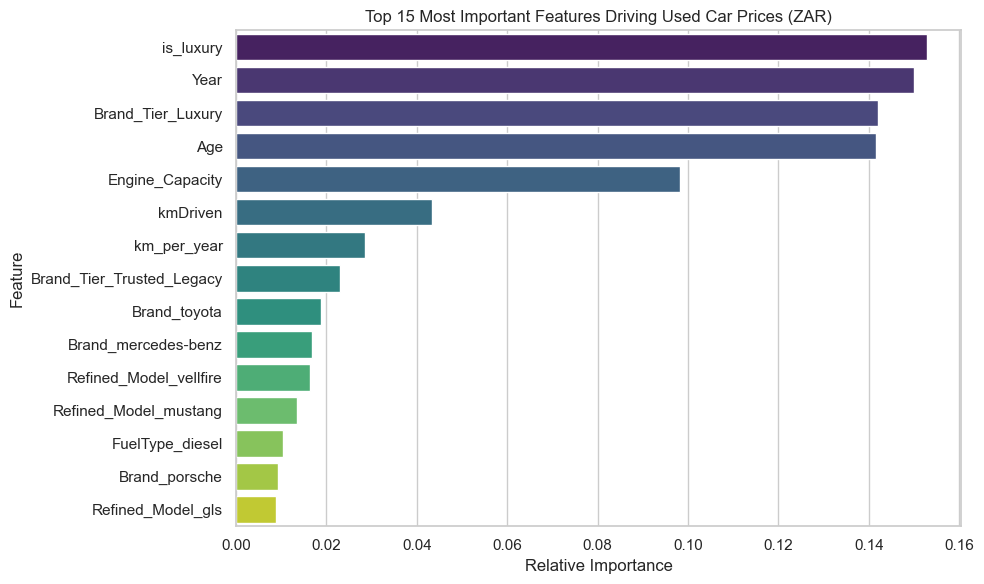

In [73]:
num_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns
cat_cols = X_train.select_dtypes(include=['object', 'string', 'category']).columns


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)


lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
lr_model.fit(X_train, y_train)

train_r2_lr = r2_score(y_train, lr_model.predict(X_train))
test_r2_lr = r2_score(y_test, lr_model.predict(X_test))

train_r2_rf = r2_score(y_train, best_rf.predict(X_train))
test_r2_rf = r2_score(y_test, best_rf.predict(X_test))

train_r2_rf = r2_score(y_train, best_rf.predict(X_train))
test_r2_rf = r2_score(y_test, best_rf.predict(X_test))

print("--- Overfitting & Underfitting Diagnostic ---")
print(f"Baseline Linear Regression -> Train R²: {train_r2_lr:.4f} | Test R²: {test_r2_lr:.4f}")
print(f"Tuned Random Forest        -> Train R²: {train_r2_rf:.4f} | Test R²: {test_r2_rf:.4f}")

y_pred_best = best_rf.predict(X_test)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Actual vs Predicted
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.4, color='teal', ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted Price (ZAR) - Tuned Random Forest')
axes[0].set_xlabel('Actual Price (ZAR)')
axes[0].set_ylabel('Predicted Price (ZAR)')

# Residual Distribution
sns.histplot(residuals, bins=50, kde=True, color='coral', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Residual Error Distribution (Actual - Predicted)')
axes[1].set_xlabel('Prediction Error (ZAR)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Inspect Top 5 Worst Prediction Errors
y_pred_best = best_rf.predict(X_test)
residuals = y_test - y_pred_best


error_df = df.loc[X_test.index, ['Brand', 'Refined_Model', 'Year', 'kmDriven']].copy()
error_df['Actual_ZAR'] = y_test
error_df['Predicted_ZAR'] = y_pred_best.round(2)
error_df['Abs_Error_ZAR'] = np.abs(residuals).round(2)

print("\n--- Top 5 Largest Prediction Errors ---")
print(error_df.sort_values(by='Abs_Error_ZAR', ascending=False)[
    ['Brand', 'Refined_Model', 'Year', 'kmDriven', 'Actual_ZAR', 'Predicted_ZAR', 'Abs_Error_ZAR']
].head(5).to_string(index=False))

feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()
importances = best_rf.named_steps['regressor'].feature_importances_

feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp['Feature'] = feat_imp['Feature'].str.replace('num__', '').str.replace('cat__', '')
top_features = feat_imp.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Most Important Features Driving Used Car Prices (ZAR)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [74]:
y_pred = best_rf.predict(X_test)
residuals = y_test - y_pred

error_analysis_df = pd.DataFrame({
    'Actual_ZAR': y_test,
    'Predicted_ZAR': y_pred,
    'Abs_Error_ZAR': np.abs(residuals)
}).sort_values(by='Abs_Error_ZAR', ascending=False)

print("\n--- Top 5 Largest Prediction Errors ---")
print(error_analysis_df.head())


--- Top 5 Largest Prediction Errors ---
       Actual_ZAR  Predicted_ZAR  Abs_Error_ZAR
3002    1488996.0   1.658045e+05   1.323191e+06
19548   2014524.0   9.138789e+05   1.100645e+06
2742    2049559.2   1.015054e+06   1.034506e+06
19427   2207217.6   1.198460e+06   1.008758e+06
6579    1664172.0   6.748036e+05   9.893684e+05


In [75]:
joblib.dump(best_rf, 'sa_used_car_pricer.pkl')
print("Model saved successfully as sa_used_car_pricer.pkl")

Model saved successfully as sa_used_car_pricer.pkl
